In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 4장 모델 훈련

## 4.1 선형 회귀

### 4.1.1 정규 방정식

In [2]:
np.random.seed(42)

m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.rand(m, 1)

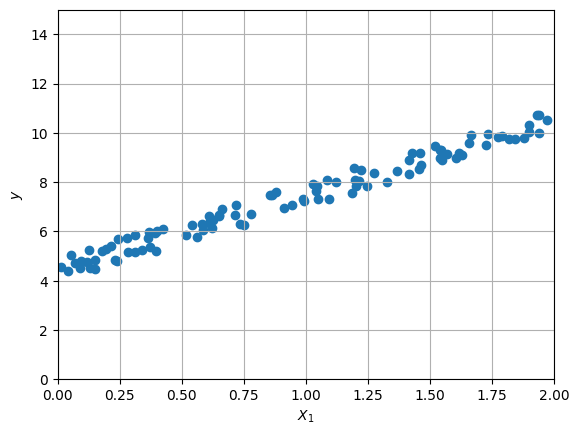

In [3]:
plt.scatter(X, y)
plt.xlabel('$X_1$')
plt.ylabel('$y$')
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

In [4]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
X_b[:5]

array([[1.        , 0.74908024],
       [1.        , 1.90142861],
       [1.        , 1.46398788],
       [1.        , 1.19731697],
       [1.        , 0.31203728]])

In [5]:
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_best

array([[4.51359766],
       [2.98323418]])

In [6]:
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
y_predict

array([[ 4.51359766],
       [10.48006601]])

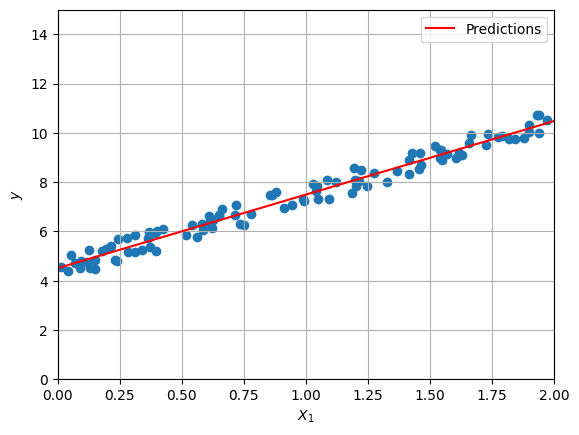

In [7]:
plt.plot(X_new, y_predict, 'r', label='Predictions')
plt.scatter(X, y)
plt.xlabel('$X_1$')
plt.ylabel('$y$')
plt.axis([0, 2, 0, 15])
plt.legend()
plt.grid()
plt.show()

In [8]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
lin_reg.intercept_, lin_reg.coef_

(array([4.51359766]), array([[2.98323418]]))

In [10]:
lin_reg.predict(X_new)

array([[ 4.51359766],
       [10.48006601]])

In [11]:
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
theta_best_svd

array([[4.51359766],
       [2.98323418]])

In [12]:
residuals, rank, s

(array([8.49565526]), np.int32(2), array([14.37020392,  4.11961067]))

In [13]:
np.linalg.pinv(X_b) @ y

array([[4.51359766],
       [2.98323418]])

## 4.2 경사 하강법

### 4.2.1 배치 경사 하강법

In [14]:
eta = 0.1
n_epochs = 1000
m = len(X_b)

In [15]:
theta = np.random.randn(2, 1)
theta_path_bgd = [theta.copy()]

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta -= eta * gradients
    theta_path_bgd.append(theta.copy())

theta

array([[4.51359766],
       [2.98323418]])

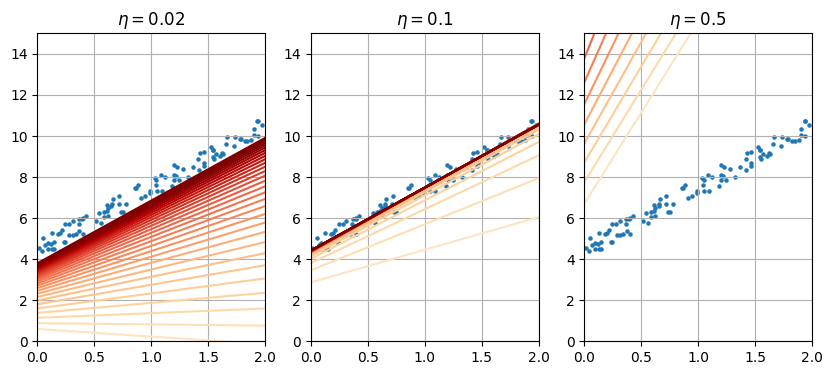

In [16]:
import matplotlib as mpl

n_show = 30
plt.figure(figsize=(10, 4))

for i, eta in enumerate([0.02, 0.1, 0.5]):
    plt.subplot(1, 3, i+1)
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr'$\eta={eta}$')
    plt.scatter(X, y, s=5)
    theta = np.random.randn(2, 1)
    
    for epoch in range(n_show):
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta -= eta * gradients

        color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_show + 0.15))
        plt.plot(X_new, X_new_b @ theta, c=color)        
    
plt.show()

### 4.2.2 확률적 경사 하강법

In [17]:
t0, t1 = 5, 50

def learning_schedule(t):
    return t0 / (t + t1)

In [18]:
n_epochs = 50
theta = np.random.randn(2, 1)
theta_path_sgd = [theta.copy()]

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index + 1]
        yi = y[random_index:random_index + 1]
        
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + iteration)
        theta -= eta * gradients
        
        theta_path_sgd.append(theta.copy())

theta

array([[4.51958766],
       [2.98789457]])

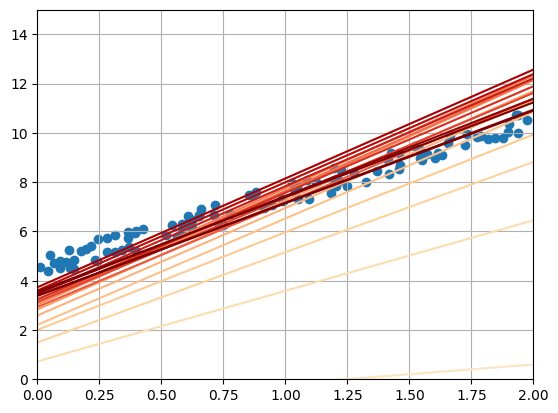

In [19]:
for i, theta in enumerate(theta_path_sgd[:20]):
    color = mpl.colors.rgb2hex(plt.cm.OrRd(i / 20 + 0.15))
    plt.plot(X_new, X_new_b @ theta, c=color)

plt.scatter(X, y)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

In [20]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, eta0=0.01, n_iter_no_change=10, random_state=42)
sgd_reg.fit(X, y.ravel())

,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide `.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",1e-05
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [21]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.47878828]), array([3.01331204]))

### 4.2.3 미니배치 경사 하강법

In [22]:
import math

theta = np.random.randn(2, 1)
theta_path_mgd = [theta.copy()]

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = math.ceil(m / minibatch_size)

for epoch in range(n_epochs):
    shuffle_indices = np.random.permutation(m)
    X_b_shuffle = X_b[shuffle_indices]
    y_shuffle = y[shuffle_indices]
    
    for iteration in range(n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b[idx : idx + minibatch_size]
        yi = y[idx : idx + minibatch_size]
        
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(iteration)
        theta -= eta * gradients
        
        theta_path_mgd.append(theta.copy())

theta

array([[4.52078838],
       [2.99287278]])

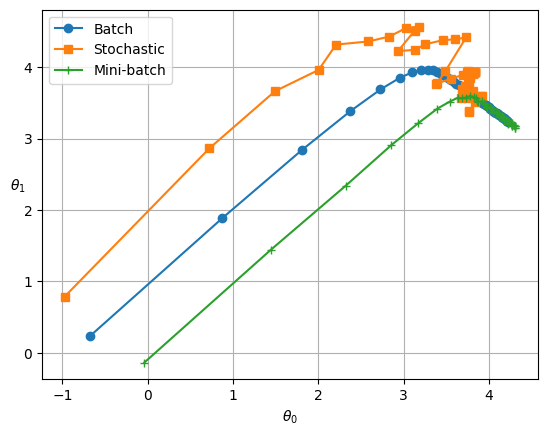

In [23]:
theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

show_limit = 50
plt.plot(theta_path_bgd[:show_limit, 0], theta_path_bgd[:show_limit, 1], '-o', label='Batch')
plt.plot(theta_path_sgd[:show_limit, 0], theta_path_sgd[:show_limit, 1], '-s', label='Stochastic')
plt.plot(theta_path_mgd[:show_limit, 0], theta_path_mgd[:show_limit, 1], '-+', label='Mini-batch')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$', rotation=0)
plt.legend()
plt.grid()
plt.show()

## 4.3 다항 회귀

In [24]:
np.random.seed(42)

m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)

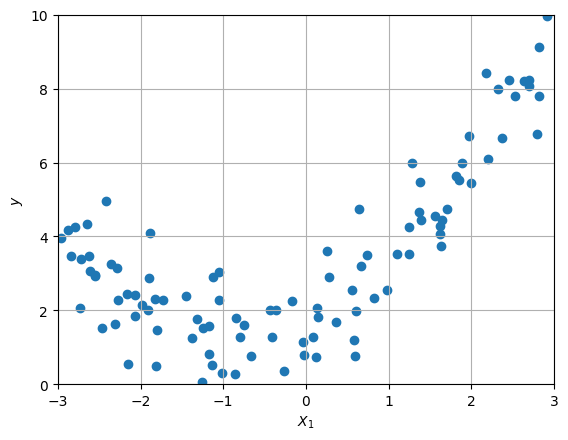

In [25]:
plt.scatter(X, y)
plt.xlabel('$X_1$')
plt.ylabel('$y$')
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [26]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(X)

In [27]:
X[0]

array([-0.75275929])

In [28]:
X_poly[0]

array([-0.75275929,  0.56664654])

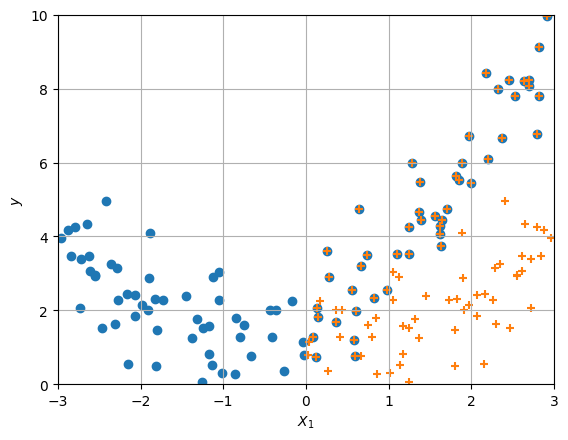

In [29]:
plt.scatter(X, y)
plt.scatter(np.sqrt(X_poly[:, 1]), y, marker='+')
plt.xlabel('$X_1$')
plt.ylabel('$y$')
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [30]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [31]:
lin_reg.intercept_, lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

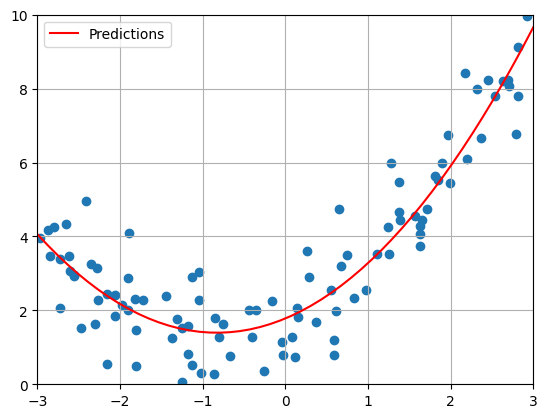

In [32]:
X_new = np.linspace(-3, 3, 50).reshape(-1, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.scatter(X, y)
plt.plot(X_new, y_new, c='red', label='Predictions')
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.legend()
plt.show()

## 4.4 학습 곡선

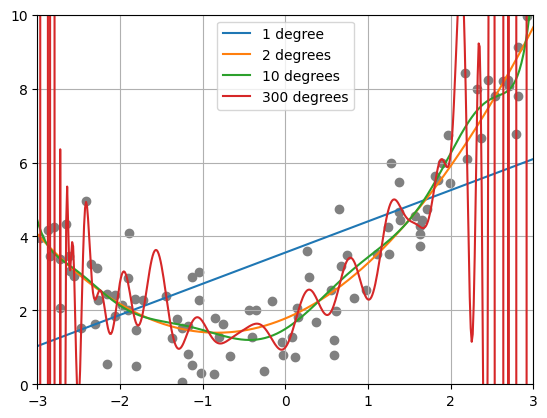

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

plt.scatter(X, y, c='gray')

X_new = np.linspace(-3, 3, 500).reshape(-1, 1)
for degree in [1, 2, 10, 300]:
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    pipeline = make_pipeline(poly_features, std_scaler, lin_reg)

    pipeline.fit(X, y)
    y_new = pipeline.predict(X_new)

    plt.plot(X_new, y_new, label=f'{degree} degree{'s' if degree > 1 else ''}')

plt.axis([-3, 3, 0, 10])
plt.grid()
plt.legend()
plt.show()

In [34]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(LinearRegression(), X, y,
                                                         train_sizes=np.linspace(0.01, 1, 50), cv=5,
                                                         scoring='neg_root_mean_squared_error')

In [35]:
train_sizes

array([ 1,  2,  4,  5,  7,  8, 10, 12, 13, 15, 16, 18, 20, 21, 23, 25, 26,
       28, 29, 31, 33, 34, 36, 37, 39, 41, 42, 44, 46, 47, 49, 50, 52, 54,
       55, 57, 58, 60, 62, 63, 65, 67, 68, 70, 71, 73, 75, 76, 78, 80])

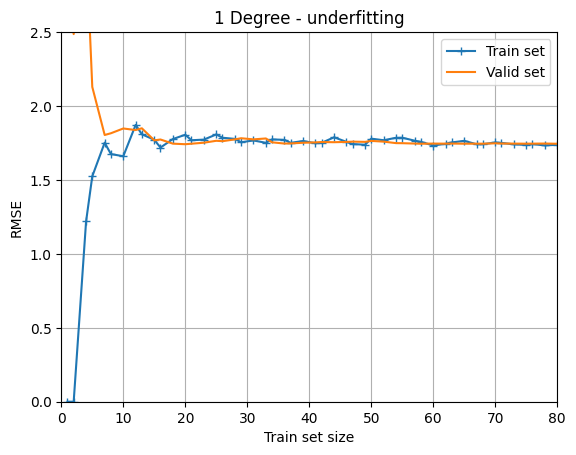

In [36]:
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, '-+', label='Train set')
plt.plot(train_sizes, valid_errors, label='Valid set')
plt.xlabel('Train set size')
plt.ylabel('RMSE')
plt.axis([0, train_sizes[-1], 0, 2.5])
plt.grid()
plt.legend()
plt.title('1 Degree - underfitting')
plt.show()

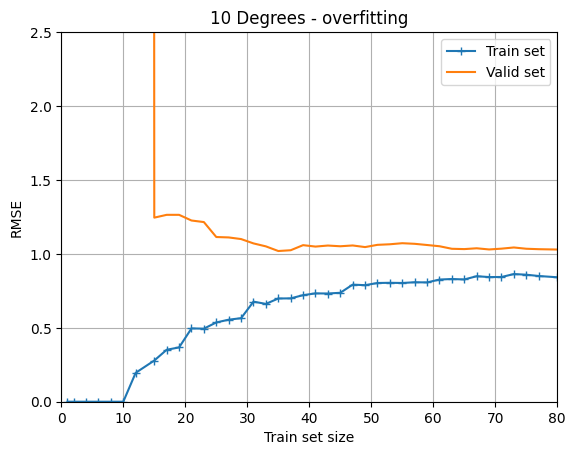

In [37]:
polynomial_regression = make_pipeline(PolynomialFeatures(degree=10, include_bias=False),
                                      LinearRegression())

train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X, y, train_sizes=np.linspace(0.01, 1, 40), cv=5, scoring='neg_root_mean_squared_error')

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, '-+', label='Train set')
plt.plot(train_sizes, valid_errors, label='Valid set')
plt.xlabel('Train set size')
plt.ylabel('RMSE')
plt.axis([0, train_sizes[-1], 0, 2.5])
plt.grid()
plt.legend()
plt.title('10 Degrees - overfitting')
plt.show()

## 4.5 규제가 있는 선형 모델

### 4.5.1 릿지 회귀

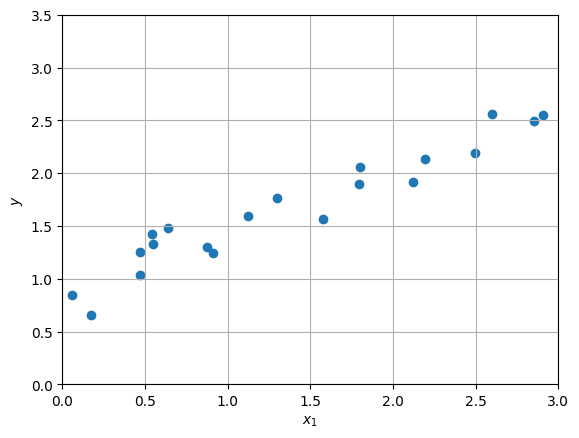

In [38]:
np.random.seed(42)

X = 3 * np.random.rand(20, 1)
y = 0.7 * X + 0.4 + np.random.rand(20, 1) / 1.5

plt.scatter(X, y)
plt.xlabel(r'$x_1$')
plt.ylabel(r'$y$')
plt.axis([0, 3, 0, 3.5])
plt.grid()
plt.show()

In [39]:
def plot_model(model, degree, alphas):
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()

    plt.scatter(X, y)
    X_new = np.linspace(0, 3, 50).reshape(-1, 1)
    for alpha in alphas:
        if alpha > 0:
            model.alpha = alpha
            model_new = model
        else:
            model_new = LinearRegression()
        
        pipeline = make_pipeline(poly_features, std_scaler, model_new)
        pipeline.fit(X, y)
        y_new = pipeline.predict(X_new)

        plt.plot(X_new, y_new, label=rf'$\alpha={alpha}$')

    plt.axis([0, 3, 0, 3.5])
    plt.grid()
    plt.legend()

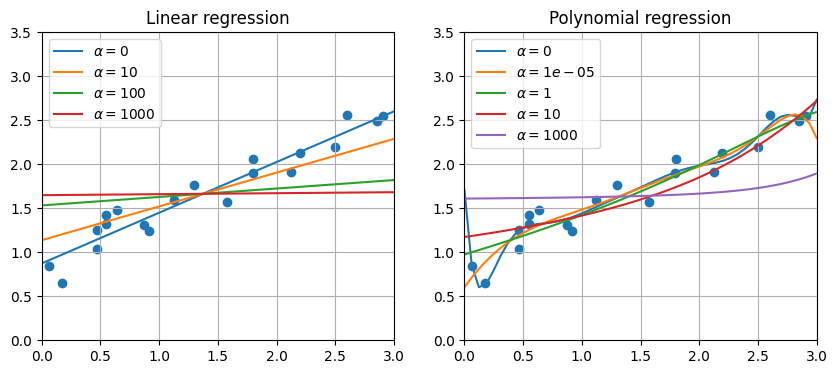

In [40]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(solver='cholesky')
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('Linear regression')
plot_model(ridge_reg, 1, [0, 10, 100, 1000])
plt.subplot(1, 2, 2)
plt.title('Polynomial regression')
plot_model(ridge_reg, 10, [0, 1e-5, 1, 10, 1000])
plt.show()

In [41]:
ridge_reg = Ridge(alpha=0.1, solver='cholesky')
ridge_reg.fit(X, y)
ridge_reg.predict([[1.5]])

array([1.73703321])

In [42]:
sgd_reg = SGDRegressor(penalty='l2', alpha=0.1/m, tol=None, max_iter=1000, eta0=0.01, random_state=42)
sgd_reg.fit(X, y.ravel())
sgd_reg.predict([[1.5]])

array([1.73702608])

### 4.5.2 라쏘 회귀

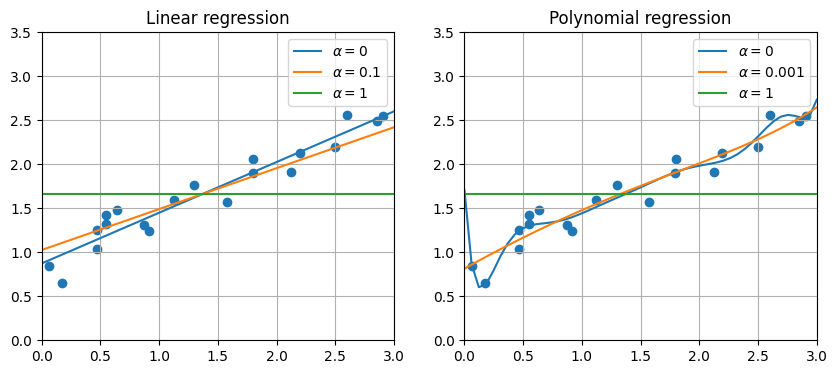

In [43]:
from sklearn.linear_model import Lasso

lasso_reg = Lasso()
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('Linear regression')
plot_model(lasso_reg, 1, [0, 0.1, 1])
plt.subplot(1, 2, 2)
plt.title('Polynomial regression')
plot_model(lasso_reg, 10, [0, 0.001, 1])
plt.show()

### 4.5.3 엘라스틱넷

In [44]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_net.fit(X, y)
elastic_net.predict([[1.5]])

array([1.72584752])

### 4.5.4 조기 종료

In [45]:
np.random.seed(42)

m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

X_train.shape, X_valid.shape

((50, 1), (50, 1))

In [46]:
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler

train_errors, valid_errors = [], []

preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False),
                              StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)

sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 400
best_valid_rmse = float('inf')
for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_train_predict = sgd_reg.predict(X_train_prep)
    y_valid_predict = sgd_reg.predict(X_valid_prep)

    train_error = root_mean_squared_error(y_train, y_train_predict)
    valid_error = root_mean_squared_error(y_valid, y_valid_predict)
    if valid_error < best_valid_rmse:
        best_valid_rmse = valid_error
        best_model = deepcopy(sgd_reg)

    train_errors.append(train_error)
    valid_errors.append(valid_error)

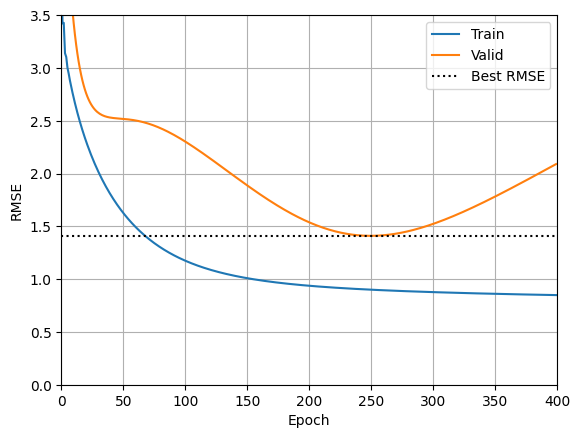

In [47]:
plt.plot(train_errors, label='Train')
plt.plot(valid_errors, label='Valid')
plt.hlines(best_valid_rmse, 0, n_epochs, color='k', linestyles='dotted', label='Best RMSE')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.legend()
plt.show()

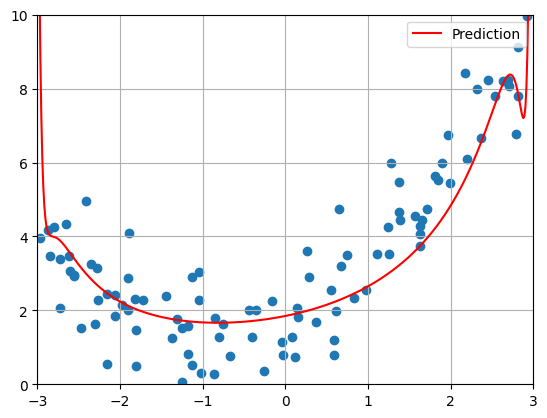

In [48]:
X_new_prep = preprocessing.transform(X_new)
y_new = best_model.predict(X_new_prep)
plt.scatter(X, y)
plt.plot(X_new, y_new, c='red', label='Prediction')
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.legend()
plt.show()

## 4.6 로지스틱 회귀

### 4.6.3 결정 경계

In [49]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

In [50]:
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [51]:
iris.data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [52]:
iris.target.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [53]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [54]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [55]:
iris.data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [56]:
from sklearn.model_selection import train_test_split

X = iris.data[['petal width (cm)']].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [57]:
X.shape, y.shape

((150, 1), (150,))

In [58]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

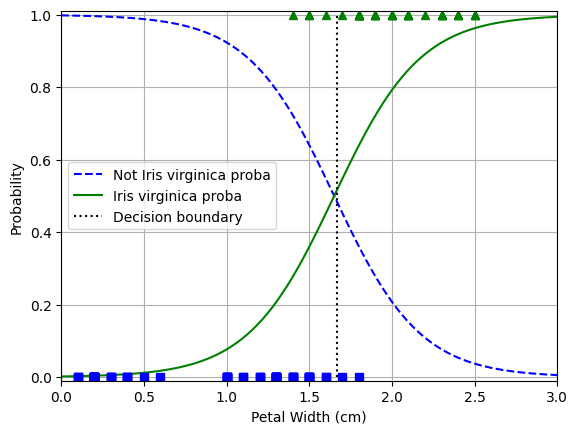

In [59]:
X_new = np.linspace(0, 3, 100).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.plot(X_new, y_proba[:, 0], 'b--', label='Not Iris virginica proba')
plt.plot(X_new, y_proba[:, 1], 'g-', label='Iris virginica proba')
plt.vlines(decision_boundary, 0, 1, color='k', linestyles='dotted', label='Decision boundary')

plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")

plt.xlabel('Petal Width (cm)')
plt.ylabel('Probability')
plt.axis([0, 3, -0.01, 1.01])
plt.grid()
plt.legend()
plt.show()

In [60]:
decision_boundary

np.float64(1.6666666666666667)

In [61]:
log_reg.predict([[1.7], [1.6]])

array([ True, False])

In [62]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg.fit(X_train, y_train)

log_reg.coef_, log_reg.intercept_

(array([[2.56143021, 2.00397536]]), array([-15.81793954]))

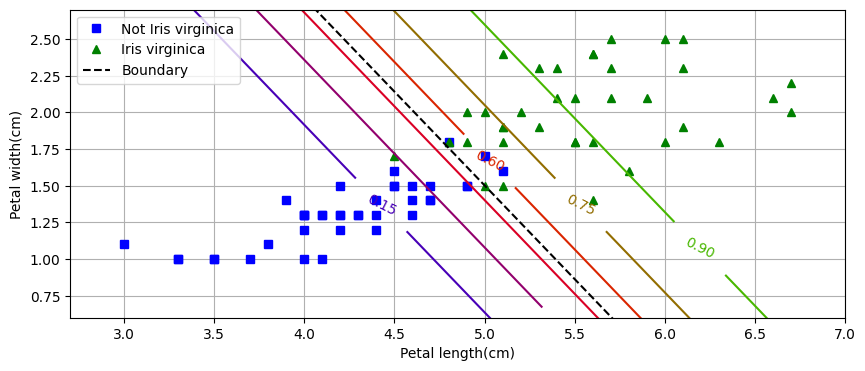

In [63]:
x0, x1 = np.meshgrid(np.linspace(1, 7, 500).reshape(-1, 1),
                     np.linspace(0, 2.7, 100).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]
y_new = log_reg.predict_proba(X_new)
Z = y_new[:, 1].reshape(100, 500)

plt.figure(figsize=(10, 4))

plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], 'bs', label='Not Iris virginica')
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], 'g^', label='Iris virginica')

left_right = np.array([2.7, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0]) / log_reg.coef_[0, 1])
plt.plot(left_right, boundary, 'k--', label='Boundary')

contour = plt.contour(x0, x1, Z, cmap=plt.cm.brg)
plt.clabel(contour)
plt.xlabel('Petal length(cm)')
plt.ylabel('Petal width(cm)')
plt.axis([*left_right, 0.6, 2.7])
plt.grid()
plt.legend()
plt.show()

### 4.6.4 소프트맥스 회귀

In [64]:
X = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = iris['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=30, random_state=42)
softmax_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",30
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multic

In [65]:
softmax_reg.predict([[5, 2]])

array([2])

In [66]:
softmax_reg.predict_proba([[5, 2]]).round(2)

array([[0.  , 0.04, 0.96]])

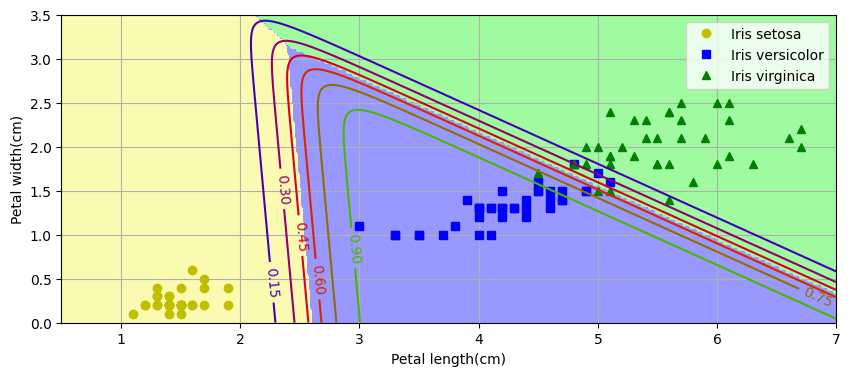

In [67]:
from matplotlib.colors import ListedColormap

def plot_contour(model):
    x0, x1 = np.meshgrid(np.linspace(0.5, 7, 500).reshape(-1, 1),
                         np.linspace(0, 3.5, 100).reshape(-1, 1))
    X_new = np.c_[x0.ravel(), x1.ravel()]
    y_proba = model.predict_proba(X_new)
    y_predict = model.predict(X_new)
    Z = y_proba[:, 1].reshape(100, 500)
    ZZ = y_predict.reshape(100, 500)
    
    plt.figure(figsize=(10, 4))
    
    plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], 'yo', label='Iris setosa')
    plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], 'bs', label='Iris versicolor')
    plt.plot(X_train[y_train == 2, 0], X_train[y_train == 2, 1], 'g^', label='Iris virginica')
    
    custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
    plt.contourf(x0, x1, ZZ, cmap=custom_cmap)
    
    contour = plt.contour(x0, x1, Z, cmap=plt.cm.brg)
    plt.clabel(contour)
    plt.xlabel('Petal length(cm)')
    plt.ylabel('Petal width(cm)')
    plt.grid()
    plt.legend()
    plt.show()

plot_contour(softmax_reg)

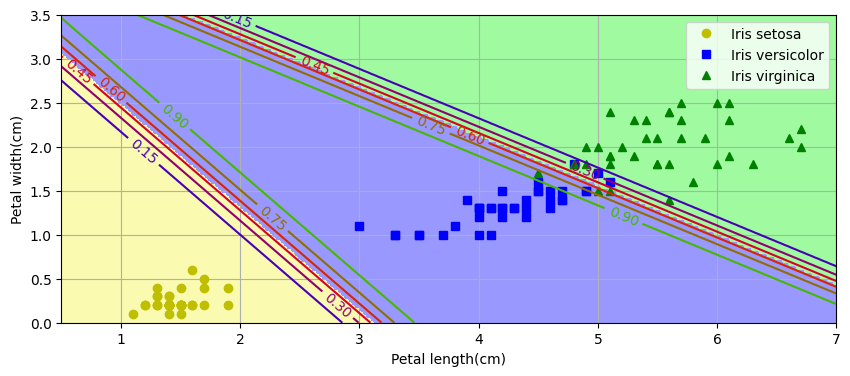

In [68]:
X = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = iris['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=1000, random_state=42)
softmax_reg.fit(X_train, y_train)

plot_contour(softmax_reg)

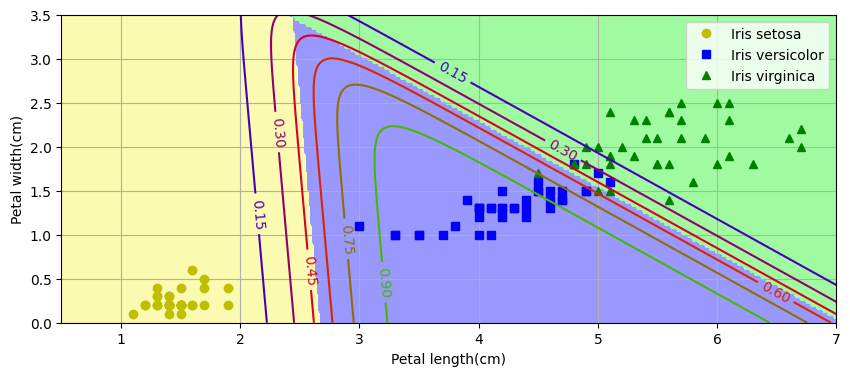

In [69]:
X = iris.data[['petal length (cm)', 'petal width (cm)']].values
y = iris['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=5, random_state=42)
softmax_reg.fit(X_train, y_train)

plot_contour(softmax_reg)